# Customer Segmentation Using Clustering
## Teresa Ferrill
### November 8, 2026

This notebook examines customer purchasing behavior using transaction data from the UCI Online Retail dataset. The objective is to identify customer groups with similar purchasing characteristics using Recency, Frequency, and Monetary (RFM) analysis and K-Means clustering.

The analysis includes data preparation, exploratory analysis, customer-level feature engineering, clustering, model evaluation, and interpretation of the resulting customer segments.

The original dataset is maintained locally as a ZIP archive and loaded directly into the notebook. Run this notebook from the notebooks directory.

### 1 - Project Overview  
#### Business Problem  
Retail businesses collect transaction data that can provide insight into customer purchasing behavior. However, customers do not necessarily purchase with the same frequency, spend similar amounts, or remain active for the same periods. Identifying these differences can help businesses develop more appropriate marketing and customer engagement strategies.  

#### Research Question  
Can customer purchasing patterns be used to identify meaningful customer segments through RFM analysis and K-Means clustering?

#### Objectives  
1. Examine transaction data to understand customer purchasing behavior.  
2. Identify and address data quality issues that could affect the analysis.
3. Develop customer-level Recency, Frequency, and Monetary (RFM) features.
4. Apply K-Means clustering to identify groups of customers with similar purchasing characteristics.
5. Evaluate cluster quality and interpret the resulting customer segments.
6. Discuss how the identified segments could support business decisions.  

### 2 - Data Collection

The dataset for this project is the Online Retail dataset from the UCI Machine Learning Repository. It contains transaction records from a UK-based online retail business between December 2010 and December 2011.  

The dataset includes transaction identifiers, product information, quantities, prices, transaction dates, customer identifiers, and customer countries.  

The original dataset is downloaded separately from the UCI Machine Learning Repository and saved locally as data/online+retail.zip. It is not included in the GitHub repository. The notebook reads the Excel workbook directly from the ZIP archive without extracting or modifying the source file. 

Source:
https://archive.ics.uci.edu/dataset/352/online+retail

In [1]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import pandas as pd

# Ensures outputs/figures/ directory exists to capture visualizations 
FIGURES_DIR = Path("../images")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Check that openpyxl is installed
try:
    import openpyxl
    print(f"openpyxl version {openpyxl.__version__} is available.")
except ImportError:
    raise ImportError(
        "openpyxl is required to read the Excel dataset. "
        "Install it using: pip install openpyxl"
    )

# Notebook is executed from the notebooks directory
DATA_DIR = Path("../data")
ZIP_PATH = DATA_DIR / "online+retail.zip"

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {ZIP_PATH.resolve()}"
    )

# Inspect the archive contents
with ZipFile(ZIP_PATH) as archive:
    print(archive.namelist())


openpyxl version 3.1.5 is available.
['Online Retail.xlsx']


In [2]:
# Load the Excel workbook
with ZipFile(ZIP_PATH) as archive:
    excel_files = [
        name for name in archive.namelist()
        if name.lower().endswith((".xlsx", ".xls"))
        and not Path(name).name.startswith("~$")
    ]

    if len(excel_files) != 1:
        raise ValueError(
            f"Expected one Excel file, found: {excel_files}"
        )

    with archive.open(excel_files[0]) as file:
        excel_bytes = BytesIO(file.read())

    df = pd.read_excel(excel_bytes)

print(f"Dataset shape: {df.shape}")
display(df.head())


Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 3 - Data Understanding

The initial review examined the dataset’s structure, data types, transaction dates, and customer coverage. Missing values and exact duplicate rows were counted to identify issues that could affect customer-level analysis.  

Additional checks examined cancellation invoices, nonpositive quantities and unit prices, and the distribution of transactions by country. These findings informed the cleaning decisions documented in Section 4.

In [3]:
# Examine dataset structure and data types
print("Dataset Information")
df.info()

# Review missing values
print("\nMissing Values")
display(
    pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing Percentage": (
            df.isna().mean() * 100
        ).round(2)
    })
)

# Identify duplicate records
print(f"\nDuplicate records: {df.duplicated().sum():,}")

# Review transaction date range
print(f"\nEarliest transaction: {df['InvoiceDate'].min()}")
print(f"Latest transaction: {df['InvoiceDate'].max()}")

# Count unique customers
print(
    f"\nUnique customers: "
    f"{df['CustomerID'].nunique():,}"
)


Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values


,Missing Count,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00



Duplicate records: 5,268

Earliest transaction: 2010-12-01 08:26:00
Latest transaction: 2011-12-09 12:50:00

Unique customers: 4,372


-------------------------------------------------------------------------------------------------------
#### Additional Transaction Quality Assessment

In [4]:
# Examine transaction characteristics before cleaning

print("Quantity Summary")
display(df["Quantity"].describe())

print("\nUnit Price Summary")
display(df["UnitPrice"].describe())

# Identify nonpositive quantities and prices
print(
    f"\nQuantity <= 0: "
    f"{(df['Quantity'] <= 0).sum():,}"
)
print(
    f"UnitPrice <= 0: "
    f"{(df['UnitPrice'] <= 0).sum():,}"
)

# Identify cancellation invoices
cancellations = (
    df["InvoiceNo"]
    .astype(str)
    .str.upper()
    .str.startswith("C")
)

print(
    f"Cancellation transaction rows: "
    f"{cancellations.sum():,}"
)

print(
    f"Unique cancellation invoices: "
    f"{df.loc[cancellations, 'InvoiceNo'].nunique():,}"
)

# Examine transaction distribution by country
print("\nTop 10 Countries")
display(df["Country"].value_counts().head(10))


Quantity Summary


count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64


Unit Price Summary


count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64


Quantity <= 0: 10,624
UnitPrice <= 0: 2,517
Cancellation transaction rows: 9,288
Unique cancellation invoices: 3,836

Top 10 Countries


Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

-------------------------------------------------------------------------------------------------------
#### Initial Data Quality Findings

The dataset contains 541,909 transaction records across eight columns, representing 4,372 unique customers. Transaction dates range from December 1, 2010, through December 9, 2011.  

The initial review identified 135,080 records (24.93%) without a customer identifier, 1,454 records (0.27%) with missing product descriptions, and 5,268 exact duplicate rows.  

Missing customer identifiers are particularly important because the planned RFM analysis requires transactions to be associated with individual customers. Records without a customer identifier were therefore excluded from customer-level analysis.  

The additional review identified 10,624 records with nonpositive quantities, 2,517 records with nonpositive unit prices, and 9,288 rows associated with cancellation invoices. The data also contains unusually large positive and negative transaction values that require consideration during cleaning.  

Most transaction records originate from the United Kingdom. The analysis retained customers from all countries while excluding records that could not support customer-level purchasing analysis.

-------------------------------------------------------------------------------------------------------
### 4 - Data Cleaning
Cleaning process to preserve the original dataset:
> 1. Missing Customer ID - Exclude  
> 2. Cancellation invoice (C prefix) - Exclude from purchase-only RFM
> 3. Quantity <= 0 - Exclude
> 4. UnitPrice <= 0 - Exclude
> 5. Exact duplicate rows - Remove (documenting the assumption)
> 6. Missing Description - Retain if other required fields are valid
> 7. Country - Retain all initially

**Cleaning process supports a purchase-only RFM analysis.**  

In [5]:
# Data Cleaning
# Preserve the original dataset
df_clean = df.copy()
initial_rows = len(df_clean)

# Track cleaning results
cleaning_summary = []

def record_step(step, before, after):
    cleaning_summary.append({
        "Step": step,
        "Rows Removed": before - after,
        "Rows Remaining": after
    })

# 1. Remove missing customer identifiers
before = len(df_clean)
df_clean = df_clean.dropna(subset=["CustomerID"])
record_step("Missing CustomerID", before, len(df_clean))

# 2. Remove cancellation invoices
before = len(df_clean)
df_clean = df_clean[
    ~df_clean["InvoiceNo"]
    .astype(str)
    .str.upper()
    .str.startswith("C")
].copy()
record_step("Cancellation invoices", before, len(df_clean))

# 3. Retain positive quantities
before = len(df_clean)
df_clean = df_clean[df_clean["Quantity"] > 0].copy()
record_step("Nonpositive quantity", before, len(df_clean))

# 4. Retain positive unit prices
before = len(df_clean)
df_clean = df_clean[df_clean["UnitPrice"] > 0].copy()
record_step("Nonpositive unit price", before, len(df_clean))

# 5. Remove exact duplicate rows
before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
record_step("Exact duplicates", before, len(df_clean))

# Display cleaning summary
display(pd.DataFrame(cleaning_summary))

print(f"Original rows: {initial_rows:,}")
print(f"Cleaned rows: {len(df_clean):,}")
print(f"Total removed: {initial_rows - len(df_clean):,}")
print(
    f"Records retained: "
    f"{len(df_clean) / initial_rows * 100:.2f}%"
)


,Step,Rows Removed,Rows Remaining
0,Missing CustomerID,135080,406829
1,Cancellation invoices,8905,397924
2,Nonpositive quantity,0,397924
3,Nonpositive unit price,40,397884
4,Exact duplicates,5192,392692


Original rows: 541,909
Cleaned rows: 392,692
Total removed: 149,217
Records retained: 72.46%


In [6]:
# Validate cleaned dataset

print("Remaining missing CustomerID:",
      df_clean["CustomerID"].isna().sum())

print("Remaining nonpositive quantities:",
      (df_clean["Quantity"] <= 0).sum())

print("Remaining nonpositive prices:",
      (df_clean["UnitPrice"] <= 0).sum())

print("Remaining duplicates:",
      df_clean.duplicated().sum())

print("Unique customers:",
      df_clean["CustomerID"].nunique())

# Verify all cleaning conditions
assert df_clean["CustomerID"].notna().all()
assert (df_clean["Quantity"] > 0).all()
assert (df_clean["UnitPrice"] > 0).all()
assert not df_clean.duplicated().any()
assert not df_clean["InvoiceNo"].astype(str).str.upper().str.startswith("C").any()


Remaining missing CustomerID: 0
Remaining nonpositive quantities: 0
Remaining nonpositive prices: 0
Remaining duplicates: 0
Unique customers: 4338


-------------------------------------------------------------------------------------------------------
#### Data Cleaning Results

The cleaning process reduced the dataset from 541,909 to 392,692 transaction records, retaining approximately 72.46% of the original observations. The largest reduction resulted from removing 135,080 records without customer identifiers. Additional exclusions included cancellation transactions, nonpositive prices, and exact duplicate records.  

No additional records were removed for nonpositive quantities because these observations had already been excluded during earlier cleaning steps.  

The cleaned dataset contains 4,338 unique customers. Validation checks confirmed that the remaining records have valid customer identifiers, positive quantities and prices, and no exact duplicates or cancellation invoices.  
  
This analysis focuses on positive purchasing activity rather than net spending after returns. Exact duplicate rows were removed under the assumption that they represented repeated records, although some may reflect legitimate transaction lines. These decisions should be considered when interpreting customer purchasing patterns and the resulting segments.  

-------------------------------------------------------------------------------------------------------
### 5 - Exploratory Data Analysis (EDA)

The exploratory analysis examined transaction-line purchasing values in the cleaned dataset. Summary statistics described the range of values, the number of purchase invoices, and the total retained positive purchasing value.  

Transaction values were visualized through the 99th percentile to show typical purchases more clearly. A second visualization used a logarithmic transformation to display the full range, including unusually large purchases. Neither visualization changed the records retained for modeling.  

Customer-level Recency, Frequency, and Monetary measures were developed in Section 6 and their distributions examined in Section 7.

In [7]:
# Section 5 - Exploratory Data Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Preserve cleaned data and calculate line revenue
df_clean["LineTotal"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Review purchasing activity
print("Transaction Line Revenue Summary")
display(df_clean["LineTotal"].describe())

print("\nUnique Invoices:",
      df_clean["InvoiceNo"].nunique())

print("\nUnique Customers:",
      df_clean["CustomerID"].nunique())

print("\nTotal Positive Purchase Value:",
      f"{df_clean['LineTotal'].sum():,.2f}")


Transaction Line Revenue Summary


count    392692.000000
mean         22.631500
std         311.099224
min           0.001000
25%           4.950000
50%          12.450000
75%          19.800000
max      168469.600000
Name: LineTotal, dtype: float64


Unique Invoices: 18532

Unique Customers: 4338

Total Positive Purchase Value: 8,887,208.89


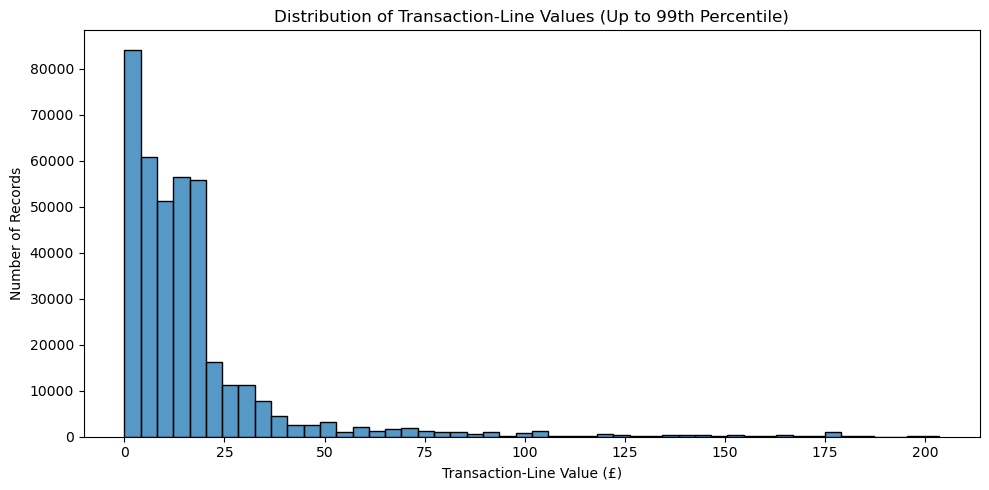

99th percentile: £203.52


In [8]:
# Visualize transaction-line purchase values
# Distribution of typical transaction-line values
# Limit the display to the 99th percentile

upper_limit = df_clean["LineTotal"].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean.loc[
        df_clean["LineTotal"] <= upper_limit,
        "LineTotal"
    ],
    bins=50
)

plt.title("Distribution of Transaction-Line Values (Up to 99th Percentile)")
plt.xlabel("Transaction-Line Value (£)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "transaction_values_99th_percentile.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"99th percentile: £{upper_limit:,.2f}")

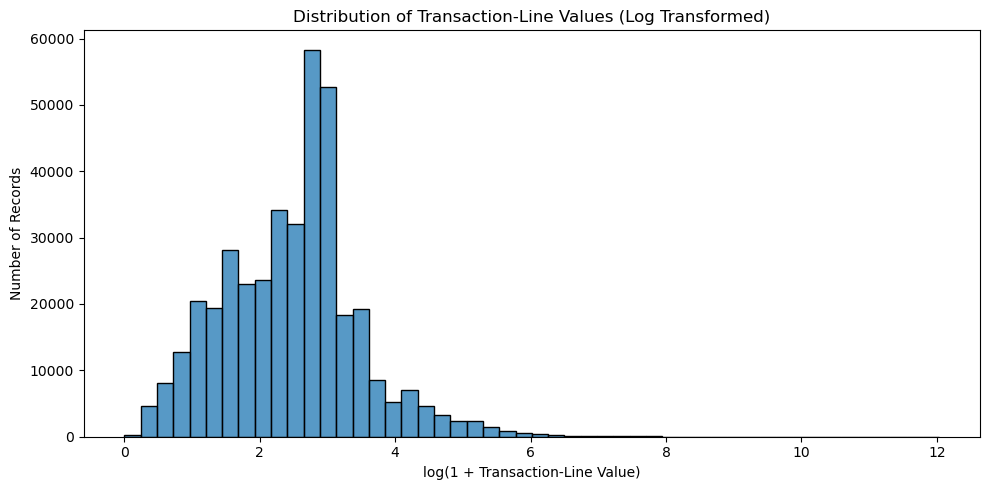

In [9]:
import numpy as np

# Log-transform values for visualization
log_values = np.log1p(df_clean["LineTotal"])

plt.figure(figsize=(10, 5))

sns.histplot(
    log_values,
    bins=50
)

plt.title("Distribution of Transaction-Line Values (Log Transformed)")
plt.xlabel("log(1 + Transaction-Line Value)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "transaction_values_log_transformed.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

#### Transaction Value Distribution

The transaction-line values are strongly right-skewed. Although the median transaction-line value is £12.45, the maximum exceeds £168,000. This large difference causes most observations to appear concentrated near zero when the full range is displayed on a linear scale.  

To better examine typical purchasing activity, the distribution was visualized using values through the 99th percentile. A logarithmic transformation was also used to display the full range without excluding unusually large purchases.  

These findings informed the development of customer-level monetary features and preparation for K-Means clustering.

-------------------------------------------------------------------------------------------------------

### 6 - Feature Engineering

The cleaned transaction data was aggregated to the customer level using Recency, Frequency, and Monetary (RFM) measures.  

Recency measures the number of calendar days since a customer’s most recent retained purchase. Frequency counts distinct purchase invoices, and Monetary totals the value of retained positive purchases.  

December 10, 2011, one day after the latest transaction, served as the reference date for calculating recency. The resulting dataset contained one record for each of the 4,338 customers.  

In [10]:
# Section 6 - RFM Feature Engineering

# Establish reference date
reference_date = (
    df_clean["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

# Aggregate transactions to customer level
rfm = df_clean.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineTotal", "sum")
).reset_index()

# Calculate recency in days
rfm["Recency"] = (
    reference_date - rfm["LastPurchase"].dt.normalize()
).dt.days

# Organize RFM features
rfm = rfm[
    ["CustomerID", "Recency", "Frequency", "Monetary"]
]

print(f"Reference date: {reference_date}")
print(f"Customer records: {len(rfm):,}")

display(rfm.head())
display(rfm[["Recency", "Frequency", "Monetary"]].describe())


Reference date: 2011-12-10 00:00:00
Customer records: 4,338


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,93.059474,4.272015,2048.688081
std,100.012264,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.750000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [11]:
# Validate RFM dataset

assert rfm["CustomerID"].is_unique
assert rfm[["Recency", "Frequency", "Monetary"]].notna().all().all()
assert (rfm["Recency"] >= 0).all()
assert (rfm["Frequency"] > 0).all()
assert (rfm["Monetary"] > 0).all()

assert len(rfm) == df_clean["CustomerID"].nunique()

print("RFM validation passed.")
print(f"Customers: {len(rfm):,}")


RFM validation passed.
Customers: 4,338


-------------------------------------------------------------------------------------------------------
### 7 - Data Processing

The customer-level RFM features were examined for skewness and extreme values. Frequency and Monetary were particularly right-skewed, with a small number of customers having much higher values than most others.  

The three features were transformed using log1p and standardized using StandardScaler. These steps reduced skewness and placed the features on comparable scales for K-Means distance calculations. Original RFM values were retained for interpreting the customer segments.

RFM Feature Summary


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,93.059474,4.272015,2048.688081
std,100.012264,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.750000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000



RFM Feature Skewness


Recency       1.25
Frequency    12.07
Monetary     19.34
dtype: float64

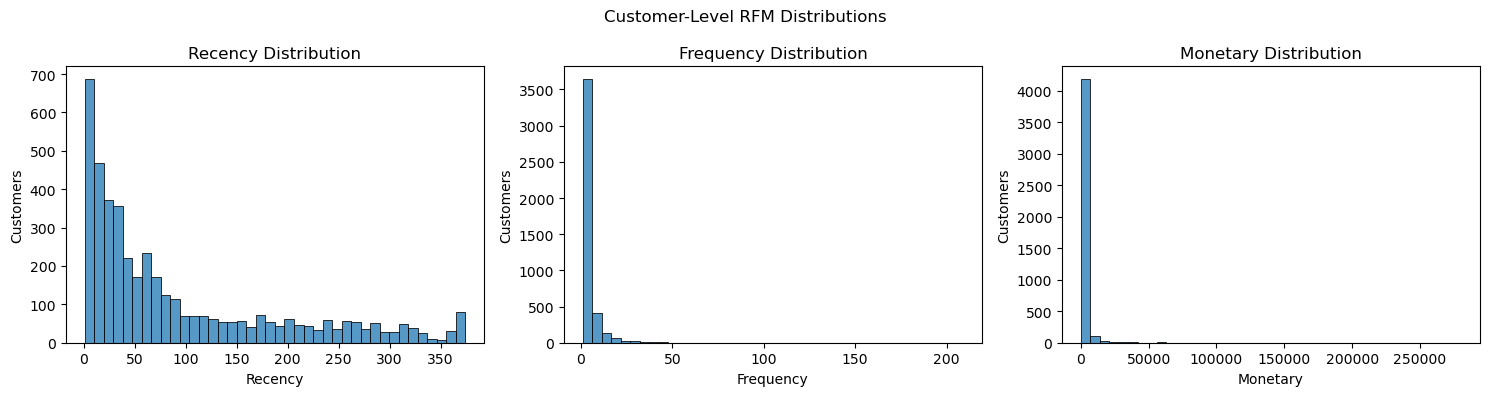

In [12]:
# Section 7 - Data Processing
# Examine customer-level RFM distributions

rfm_features = ["Recency", "Frequency", "Monetary"]

# Summary statistics
print("RFM Feature Summary")
display(rfm[rfm_features].describe())

# Measure skewness
print("\nRFM Feature Skewness")
display(rfm[rfm_features].skew().round(2))

# Visualize original feature distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, rfm_features):
    sns.histplot(
        rfm[feature],
        bins=40,
        ax=ax
    )
    ax.set_title(f"{feature} Distribution")
    ax.set_xlabel(feature)
    ax.set_ylabel("Customers")

plt.suptitle("Customer-Level RFM Distributions")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "rfm_original_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [13]:
# Examine RFM percentiles and extreme values

rfm_percentiles = rfm[rfm_features].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
)

print("RFM Feature Percentiles")
display(rfm_percentiles)

# Identify highest-spending customers
print("\nTop 10 Customers by Monetary Value")
display(
    rfm.nlargest(10, "Monetary")[
        ["CustomerID", "Recency", "Frequency", "Monetary"]
    ]
)

RFM Feature Percentiles


,Recency,Frequency,Monetary
0.50,51.00,2.0,668.5700
0.75,142.75,5.0,1660.5975
0.90,263.30,9.0,3640.8410
0.95,312.00,13.0,5789.9995
0.99,369.63,30.0,19780.4878
1.00,374.00,209.0,280206.0200



Top 10 Customers by Monetary Value


,CustomerID,Recency,Frequency,Monetary
1689,14646.0,2,73,280206.02
4201,18102.0,1,60,259657.30
3728,17450.0,9,46,194390.79
3008,16446.0,1,2,168472.50
1879,14911.0,2,201,143711.17
55,12415.0,25,21,124914.53
1333,14156.0,10,55,117210.08
3771,17511.0,3,31,91062.38
2702,16029.0,39,63,80850.84
0,12346.0,326,1,77183.60


#### RFM Distribution Findings

The customer-level RFM features show different degrees of right-skewness. Recency has a skewness of 1.25, while Frequency and Monetary have substantially higher skewness values of 12.07 and 19.34, respectively.

The percentile analysis indicates that a relatively small number of customers have unusually high purchasing frequency or monetary values. These observations may strongly influence distance-based clustering if the original values are used without preprocessing.

The next step is to examine logarithmic transformations and standardization to reduce the influence of extreme values and make the RFM features more comparable for K-Means clustering.  

-------------------------------------------------------------------------------------------------------

#### Logarithmic Transformation

In [14]:
# Preserve the original customer-level RFM data
rfm_transformed = rfm[rfm_features].copy()

# Apply log1p transformation to reduce right-skewness
rfm_transformed = np.log1p(rfm_transformed)

# Compare skewness before and after transformation
skewness_comparison = pd.DataFrame({
    "Original": rfm[rfm_features].skew(),
    "Log Transformed": rfm_transformed.skew()
}).round(2)

print("RFM Skewness Comparison")
display(skewness_comparison)


RFM Skewness Comparison


,Original,Log Transformed
Recency,1.25,-0.33
Frequency,12.07,1.21
Monetary,19.34,0.40


#### Visualize log-transformed RFM features

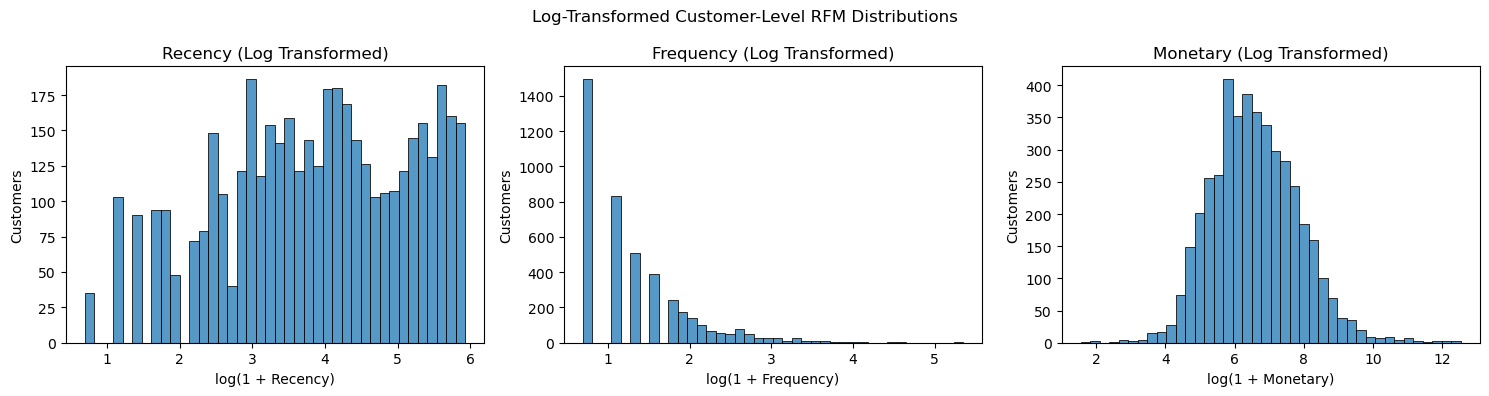

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, rfm_features):
    sns.histplot(
        rfm_transformed[feature],
        bins=40,
        ax=ax
    )

    ax.set_title(f"{feature} (Log Transformed)")
    ax.set_xlabel(f"log(1 + {feature})")
    ax.set_ylabel("Customers")

plt.suptitle("Log-Transformed Customer-Level RFM Distributions")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "rfm_log_transformed_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#### Feature Scaling

In [16]:
from sklearn.preprocessing import StandardScaler

# Standardize log-transformed RFM features
scaler = StandardScaler()

rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_transformed),
    columns=rfm_features,
    index=rfm.index
)

print("Scaled RFM Feature Summary")
display(rfm_scaled.describe().round(3))

# Validate scaled features
assert rfm_scaled.shape == (len(rfm), 3)
assert np.isfinite(rfm_scaled.to_numpy()).all()

print("\nRFM scaling validation passed.")
print(f"Customer records prepared: {len(rfm_scaled):,}")


Scaled RFM Feature Summary


,Recency,Frequency,Monetary
count,4338.000,4338.000,4338.000
mean,0.000,-0.000,-0.000
std,1.000,1.000,1.000
min,-2.421,-0.955,-3.998
25%,-0.698,-0.955,-0.684
50%,0.072,-0.362,-0.065
75%,0.850,0.653,0.657
max,1.584,5.859,4.732



RFM scaling validation passed.
Customer records prepared: 4,338


#### Feature Transformation and Scaling

Logarithmic transformations reduced the right-skewness of the RFM features. Recency skewness changed from 1.25 to -0.33, Frequency decreased from 12.07 to 1.21, and Monetary decreased from 19.34 to 0.40. These results indicate that the transformations reduced the influence of unusually large values, particularly for Frequency and Monetary.

The transformed features were then standardized using `StandardScaler` so that each variable would contribute on a comparable numerical scale to the distance calculations used by K-Means clustering.

The original customer-level RFM values were preserved for subsequent cluster interpretation. The transformed and standardized dataset was used as the input for clustering.

-------------------------------------------------------------------------------------------------------

### 8 - K-Means Clustering

K-Means clustering was applied to the transformed and standardized RFM features. Models with two through ten clusters were evaluated using the same customer dataset.  

Two measures supported the comparison:  
- Inertia: Measured how closely customers were grouped around their assigned cluster centers.  
- Silhouette score: Assessed separation between clusters. Scores were calculated using a reproducible sample of 2,000 customers.

Each model used random_state=42 and ten centroid initializations. Cluster selection considered these evaluation results alongside the usefulness of the customer profiles.  

In [17]:
# Section 8 - K-Means Clustering
# Evaluate alternative numbers of clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_range = range(2, 11)  # provides a reasonable initial comparison of cluster counts without testing an unnecessarily large range

inertia_values = []
silhouette_values = []

for k in cluster_range:

    # Fit K-Means using standardized RFM features
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,  #makes the results reproducible
        n_init=10  # evaluates multiple centroid initializations and retains the best solution by inertia
    )

    cluster_labels = kmeans.fit_predict(rfm_scaled)

    # Record within-cluster sum of squares
    inertia_values.append(kmeans.inertia_)

    # Evaluate cluster separation
    silhouette_values.append(
        silhouette_score(
            rfm_scaled,
            cluster_labels,
            sample_size=2000,   #estimates silhouette scores using a reproducible sample of 2,000 customers, reducing computation time
            random_state=42
        )
    )

# Summarize evaluation results
cluster_evaluation = pd.DataFrame({
    "Clusters": list(cluster_range),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

print("K-Means Cluster Evaluation")
display(cluster_evaluation.round(4))


K-Means Cluster Evaluation


,Clusters,Inertia,Silhouette Score
0,2,6476.5069,0.4252
1,3,4858.2441,0.3285
2,4,3925.4256,0.3292
3,5,3269.2747,0.3197
4,6,2841.4171,0.3153
5,7,2532.9847,0.3110
6,8,2325.0754,0.3009
7,9,2156.0197,0.2967
8,10,1989.4049,0.2746


In [ ]:
# Visualize K-Means evaluation results

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Elbow Method
axes[0].plot(
    cluster_evaluation["Clusters"],
    cluster_evaluation["Inertia"],
    marker="o"
)

axes[0].set_title("K-Means Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(cluster_range))
axes[0].grid(alpha=0.3)

# Silhouette Scores
axes[1].plot(
    cluster_evaluation["Clusters"],
    cluster_evaluation["Silhouette Score"],
    marker="o"
)

axes[1].set_title("K-Means Silhouette Scores")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(cluster_range))
axes[1].grid(alpha=0.3)

plt.suptitle("K-Means Cluster Count Evaluation")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "kmeans_cluster_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Clustering Results

The two-cluster model achieved the highest sampled silhouette score of 0.4252. Inertia decreased as the number of clusters increased, but the elbow plot did not identify one clear cluster count.  

Two-, three-, and four-cluster solutions were then compared using customer counts and original-scale RFM profiles. Four clusters were selected because they distinguished additional purchasing patterns, despite having a lower sampled silhouette score of 0.3292.  

-------------------------------------------------------------------------------------------------------

### 9 - Cluster Evaluation

The two-, three-, and four-cluster solutions were compared using customer counts, median RFM measures, and total retained positive purchasing value.  

Two clusters provided a broad separation between customers with higher and lower purchasing activity. Three clusters added detail, while four clusters distinguished recent low-spend customers, established moderate-value customers, inactive low-value customers, and high-value active customers.  

The four-cluster solution was selected for its business interpretability. Its lower silhouette score indicates weaker separation than the two-cluster solution, so the segments should be treated as descriptive groups rather than fixed customer categories.

In [ ]:
# Section 9 - Cluster Evaluation
# Compare customer characteristics for 2, 3, and 4 clusters

candidate_clusters = [2, 3, 4]

cluster_comparisons = {}

for k in candidate_clusters:

    # Fit K-Means using standardized RFM features
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    # Preserve original RFM values for interpretation
    rfm_candidate = rfm.copy()
    rfm_candidate["Cluster"] = labels

    # Summarize customer characteristics
    cluster_summary = (
        rfm_candidate.groupby("Cluster")
        .agg(
            Customers=("CustomerID", "count"),
            Median_Recency=("Recency", "median"),
            Median_Frequency=("Frequency", "median"),
            Median_Monetary=("Monetary", "median"),
            Total_Monetary=("Monetary", "sum")
        )
        .reset_index()
    )

    # Calculate percentage of customers in each cluster
    cluster_summary["Customer_Percent"] = (
        cluster_summary["Customers"] / len(rfm_candidate) * 100
    )

    # Store results for later comparison
    cluster_comparisons[k] = cluster_summary

    print(f"\n{k}-Cluster Solution")
    display(cluster_summary.round(2))


In [ ]:
# Validate cluster comparison results

for k, summary in cluster_comparisons.items():

    assert len(summary) == k

    assert summary["Customers"].sum() == len(rfm)

    assert np.isclose(
        summary["Customer_Percent"].sum(),
        100
    )

    assert np.isclose(
        summary["Total_Monetary"].sum(),
        rfm["Monetary"].sum()
    )

    print(f"{k}-cluster solution validation passed.")


#### Cluster Evaluation Findings

The two-cluster solution achieved the highest silhouette score (0.4252), but it primarily separated customers into broad groups based on purchasing activity and monetary value.

The three-cluster solution provided additional differentiation between highly active, moderately active, and less active customers.

The four-cluster solution identified more detailed differences in customer purchasing behavior, including recently active customers with relatively low purchasing value, moderately active customers, customers with long periods since their last purchase, and highly active customers with substantial purchasing value.

Although the four-cluster silhouette score (0.3292) was lower than the two-cluster score, the additional segments provide potentially useful distinctions for customer engagement, retention, and marketing strategies.

Based on these findings, **four clusters were selected for the final customer segmentation**, prioritizing business interpretability while acknowledging the tradeoff in statistical separation.

-------------------------------------------------------------------------------------------------------

### 10 - Business Interpretation

The selected four-cluster model assigned all 4,338 customers to a segment. Original-scale RFM measures were used to describe each group and consider possible business applications.  

High-value active customers represented 16.55% of customers and accounted for 64.73% of retained positive purchasing value. Inactive low-value customers represented 35.71% of customers but contributed 6.28% of purchasing value.  

These differences suggested potential uses for retention, repeat-purchase, and re-engagement efforts. The proposed strategies were based on observed purchasing patterns; their effectiveness was not tested in this analysis.

In [ ]:
# Section 10 - Business Interpretation
# Fit the selected four-cluster K-Means model

final_k = 4

final_kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

final_cluster_labels = final_kmeans.fit_predict(rfm_scaled)

# Preserve original RFM values for interpretation
rfm_segmented = rfm.copy()

# Assign each customer to a cluster
rfm_segmented["Cluster"] = final_cluster_labels

print("Final Customer Segmentation")
print(f"Selected number of clusters: {final_k}")
print(f"Customers assigned: {len(rfm_segmented):,}")

display(rfm_segmented.head())

In [ ]:
# Summarize final customer segments

segment_profiles = (
    rfm_segmented.groupby("Cluster")
    .agg(
        Customers=("CustomerID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Total_Monetary=("Monetary", "sum")
    )
    .reset_index()
)

# Calculate customer and monetary shares
segment_profiles["Customer_Percent"] = (
    segment_profiles["Customers"]
    / len(rfm_segmented) * 100
)

segment_profiles["Monetary_Percent"] = (
    segment_profiles["Total_Monetary"]
    / rfm_segmented["Monetary"].sum() * 100
)

print("Final Customer Segment Profiles")
display(segment_profiles.round(2))

In [ ]:
# Validate final customer segmentation

assert len(rfm_segmented) == len(rfm)

assert rfm_segmented["CustomerID"].is_unique

assert rfm_segmented["Cluster"].nunique() == final_k

assert segment_profiles["Customers"].sum() == len(rfm)

assert np.isclose(
    segment_profiles["Customer_Percent"].sum(),
    100
)

assert np.isclose(
    segment_profiles["Monetary_Percent"].sum(),
    100
)

assert np.isclose(
    segment_profiles["Total_Monetary"].sum(),
    rfm["Monetary"].sum()
)

print("Final customer segmentation validation passed.")

### Cluster RFM Profiles

The following figure compares the median original-scale RFM values across the four customer segments. Separate panels are used because the three measures have different units and scales. Lower recency indicates a more recent purchase, whereas higher frequency and monetary values indicate more purchasing activity and retained positive purchasing value. These are descriptive cluster profiles, not measures of campaign effectiveness.  

In [ ]:
# Visualize original-scale median RFM profiles for each customer cluster
# Requires segment_profiles from the preceding customer segmentation summary.

profile_metrics = [
    ("Median_Recency", "Recency", "Days since last purchase"),
    ("Median_Frequency", "Frequency", "Distinct purchase invoices"),
    ("Median_Monetary", "Monetary", "Median retained positive purchasing value (£)"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
cluster_labels = segment_profiles["Cluster"].astype(str)

for ax, (column, title, ylabel) in zip(axes, profile_metrics):
    bars = ax.bar(cluster_labels, segment_profiles[column])
    ax.set_title(f"Median {title} by Cluster")
    ax.set_xlabel("Cluster")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, segment_profiles[column].max() * 1.18)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    for bar, value in zip(bars, segment_profiles[column]):
        label = f"£{value:,.0f}" if column == "Median_Monetary" else f"{value:,.0f}"
        ax.annotate(label, (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9)

fig.suptitle("Customer Segment RFM Profiles (Original Scale)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cluster_rfm_profiles.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", FIGURES_DIR / "cluster_rfm_profiles.png")

#### Customer Distribution by Cluster

This visualization shows the percentage of customers assigned to each of the four clusters. It helps illustrate the relative size of each customer segment.

In [ ]:
# Visualize customer distribution by cluster

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    segment_profiles["Cluster"].astype(str),
    segment_profiles["Customer_Percent"]
)

# Display percentages above each bar
for bar, percent in zip(
    bars,
    segment_profiles["Customer_Percent"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{percent:.2f}%",
        ha="center",
        va="bottom"
    )

ax.set_title("Customer Distribution by Cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Percentage of Customers (%)")
ax.set_ylim(
    0,
    segment_profiles["Customer_Percent"].max() * 1.2
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "customer_distribution_by_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print("Saved:", FIGURES_DIR / "customer_distribution_by_cluster.png")


#### Customer Distribution and Purchasing Value

This visualization compares the percentage of customers in each cluster with the percentage of total retained positive purchasing value attributed to that cluster.

The comparison helps identify whether purchasing value is concentrated among particular customer segments.

In [ ]:
# Compare customer share and purchasing-value share

x = np.arange(len(segment_profiles))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

customer_bars = ax.bar(
    x - width / 2,
    segment_profiles["Customer_Percent"],
    width,
    label="Customers (%)"
)

monetary_bars = ax.bar(
    x + width / 2,
    segment_profiles["Monetary_Percent"],
    width,
    label="Purchasing Value (%)"
)

# Display percentages above the bars
for bars in [customer_bars, monetary_bars]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.7,
            f"{height:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_title(
    "Customer Distribution vs. Purchasing Value by Cluster"
)
ax.set_xlabel("Cluster")
ax.set_ylabel("Percentage (%)")

ax.set_xticks(x)
ax.set_xticklabels(
    segment_profiles["Cluster"].astype(str)
)

ax.set_ylim(
    0,
    max(
        segment_profiles["Customer_Percent"].max(),
        segment_profiles["Monetary_Percent"].max()
    ) * 1.2
)

ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "customer_vs_monetary_share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
# Verify that both figures were saved

for filename in [
    "customer_distribution_by_cluster.png",
    "customer_vs_monetary_share.png"
]:
    figure_path = FIGURES_DIR / filename

    assert figure_path.exists(), f"Missing figure: {filename}"

    print(f"Saved: {figure_path.name}")

#### Customer Segmentation Visualization Findings

The customer distribution analysis shows that the four clusters contain different proportions of the customer population.  

Cluster 2 represents the largest segment, accounting for 35.71% of customers, but contributes only 6.28% of total retained positive purchasing value. These customers generally have longer periods since their last purchase and relatively low purchasing frequency and monetary value.  

In contrast, Cluster 3 represents only 16.55% of customers but accounts for 64.73% of total retained positive purchasing value. Customers in this segment generally purchase more frequently, have higher monetary values, and have purchased more recently.  

Clusters 0 and 1 represent additional purchasing patterns, including relatively recent lower-spend customers and customers with moderate purchasing activity.  

These findings suggest that different customer segments may benefit from different engagement strategies. For example, high-value active customers may warrant retention efforts, while customers with longer periods of inactivity may be candidates for re-engagement campaigns.  

Because the analysis uses historical transaction data, these findings describe observed purchasing behavior rather than predicting future customer activity.  

-------------------------------------------------------------------------------------------------------

#### Customer Segment Profiles and Business Recommendations
<table style="margin-left: 0; margin-right: auto;">
  <thead>
    <tr>
      <th>Cluster</th>
      <th>Segment Name</th>
      <th>Business Application</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>0</td>
      <td>Recent Low-Spend Customers</td>
      <td>Encourage repeat purchases</td>
    </tr>
    <tr>
      <td>1</td>
      <td>Established Moderate-Value Customers</td>
      <td>Increase engagement</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Inactive Low-Value Customers</td>
      <td>Targeted re-engagement</td>
    </tr>
    <tr>
      <td>3</td>
      <td>High-Value Active Customers</td>
      <td>Retention and loyalty</td>
    </tr>
  </tbody>
</table>

The segment names and suggested business applications are based on observed RFM characteristics. These recommendations represent potential strategies and have not been evaluated for effectiveness.  

-------------------------------------------------------------------------------------------------------

### 11 - Conclusions

#### Key Findings

This project examined whether customer purchasing behavior could be used to identify meaningful customer segments using Recency, Frequency, and Monetary (RFM) analysis and K-Means clustering.

After cleaning the Online Retail dataset, 392,692 transaction records representing 4,338 customers were retained for analysis. Customer-level RFM features were developed, log-transformed, and standardized before clustering.

K-Means models containing two through ten clusters were evaluated using inertia and silhouette scores. Although the two-cluster solution achieved the highest sampled silhouette score (0.4252), the four-cluster solution was selected because it provided additional distinctions in customer purchasing behavior. The selected model achieved a sampled silhouette score of 0.3292.

The four segments included recent low-spend customers, established moderate-value customers, inactive low-value customers, and high-value active customers.

One of the most significant findings was the concentration of purchasing value among high-value active customers. Cluster 3 contained 16.55% of customers but accounted for 64.73% of retained positive purchasing value. In contrast, Cluster 2 contained 35.71% of customers but contributed only 6.28% of purchasing value.

These differences suggest that customer segmentation may support more targeted retention, engagement, and re-engagement strategies.

#### Limitations

Several limitations should be considered when interpreting the results.

- **Historical data:** The dataset covers transactions from December 2010 through December 2011. Customer purchasing patterns may differ under current market conditions.
- **Single retailer:** The analysis represents one online retailer and may not generalize to other businesses or industries.
- **Data exclusions:** Transactions without customer identifiers, cancellations, nonpositive quantities or prices, and exact duplicate records were excluded. Monetary values therefore represent retained positive purchases rather than net revenue after returns.
- **Feature selection:** The clustering model uses only Recency, Frequency, and Monetary values. Other customer characteristics, including product preferences and purchasing trends, were not considered.
- **Cluster selection:** The four-cluster solution provided greater business interpretability but had a lower sampled silhouette score than the two-cluster solution.
- **Business outcomes:** The identified segments and suggested strategies have not been tested to determine whether they improve customer retention, engagement, or revenue.

#### Future Improvements

Future work could extend the analysis by incorporating additional customer characteristics, including product categories, average order value, and changes in purchasing frequency over time.

Alternative clustering methods, such as hierarchical clustering or DBSCAN, could be evaluated to determine whether they identify different customer groupings. Additional analysis could also examine cluster stability across different samples or time periods.

Another potential improvement would be to evaluate the effectiveness of segment-specific business strategies. For example, targeted campaigns could be tested to determine whether they increase repeat purchases or improve customer retention.

Finally, the analysis could be extended into a repeatable customer segmentation pipeline that refreshes RFM measures and customer assignments as new transaction data becomes available.